# 02 - Stationarity and Fractional Differentiation

**Purpose.** Find the smallest amount of differencing that makes my price series
stationary while keeping as much memory as possible.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.color": "#D9E2E4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.width", 160)

TEAL, AMBER, RED, GREY = "#0E7C86", "#C77700", "#C0392B", "#7A8B90"

RAW = Path("../data/01-raw")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

bars = {path.stem: pd.read_parquet(path) for path in sorted(RAW.glob("*.parquet"))}
log_prices = pd.DataFrame(
    {ticker: np.log(frame["adj_close"]) for ticker, frame in bars.items()}
)

print(f"Loaded {len(bars)} tickers, {len(log_prices):,} rows")
print(f"Working in log prices: SPY runs {log_prices['SPY'].iloc[0]:.3f} "
      f"to {log_prices['SPY'].iloc[-1]:.3f}")

Loaded 11 tickers, 5,032 rows
Working in log prices: SPY runs 4.394 to 6.358


### The Augmented Dickey-Fuller test

Before I can say a series is stationary I need a test, and I would rather write
it than call one, because the whole point of this notebook is understanding what
the number means.

The ADF test fits this regression:

$$\Delta y_t = \alpha + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \varepsilon_t$$

The coefficient I care about is $\gamma$. If the series is a random walk then
today's level tells me nothing about tomorrow's change, so $\gamma$ should be
zero. If the series is stationary then it pulls back toward its mean, so a high
level today implies a fall tomorrow, and $\gamma$ should be clearly negative.

The test statistic is the t-statistic on $\gamma$. It does not follow a normal
distribution, so I compare it against MacKinnon's tabulated critical values
rather than the usual 1.96. **More negative means more stationary.** At 95%
confidence the threshold is −2.86.

The lagged difference terms are there to soak up any autocorrelation in the
errors, which would otherwise bias the estimate. I pick how many with the
Schwert rule, the standard default.

In [2]:
# MacKinnon critical values for the constant-only ADF regression.
ADF_CRITICAL = {0.01: -3.43, 0.05: -2.86, 0.10: -2.57}


def adf_statistic(series, max_lag=None):
    """Return the ADF t-statistic on gamma. More negative means more stationary."""
    y = pd.Series(series).dropna().to_numpy(dtype=float)
    n = len(y)

    # Schwert rule for how many lagged differences to include.
    if max_lag is None:
        max_lag = int(np.ceil(12 * (n / 100) ** 0.25))

    dy = np.diff(y)
    start = max_lag + 1

    target = dy[start - 1:]
    columns = [np.ones(len(target)), y[start - 1 : -1]]

    for lag in range(1, max_lag + 1):
        columns.append(dy[start - 1 - lag : -lag])

    design = np.column_stack(columns)
    beta, *_ = np.linalg.lstsq(design, target, rcond=None)

    residuals = target - design @ beta
    dof = len(target) - design.shape[1]
    variance = residuals @ residuals / dof
    standard_error = np.sqrt(variance * np.linalg.inv(design.T @ design)[1, 1])

    return beta[1] / standard_error


def is_stationary(statistic, confidence=0.05):
    """Compare an ADF statistic against its critical value."""
    return statistic < ADF_CRITICAL[confidence]

In [3]:
rng = np.random.default_rng(0)
n = 5_000

random_walk = np.cumsum(rng.normal(0, 1, n))
white_noise = rng.normal(0, 1, n)

ar_one = np.zeros(n)
for i in range(1, n):
    ar_one[i] = 0.99 * ar_one[i - 1] + rng.normal()

for name, series in [
    ("random walk", random_walk),
    ("white noise", white_noise),
    ("AR(1), phi = 0.99", ar_one),
]:
    statistic = adf_statistic(series)
    verdict = "stationary" if is_stationary(statistic) else "NOT stationary"
    print(f"{name:20s} ADF {statistic:9.4f}   {verdict}")

random walk          ADF   -1.5642   NOT stationary
white noise          ADF  -11.4495   stationary
AR(1), phi = 0.99    ADF   -4.5110   stationary


### How badly do my prices fail?

Now the same test on my actual data. I run it on log prices and on log returns
for every ticker, so I can see both ends of the trade-off before I go looking
for the middle.

In [4]:
endpoints = pd.DataFrame([
    {
        "ticker": ticker,
        "adf_log_price": adf_statistic(series),
        "adf_log_return": adf_statistic(series.diff()),
    }
    for ticker, series in log_prices.items()
]).set_index("ticker").sort_index()

endpoints["price_stationary"] = endpoints["adf_log_price"].apply(is_stationary)
endpoints["return_stationary"] = endpoints["adf_log_return"].apply(is_stationary)

endpoints.round(3)

,adf_log_price,adf_log_return,price_stationary,return_stationary
ticker,,,,
AAPL,-0.848,-11.696,False,True
GE,-1.699,-11.474,False,True
INTC,-1.415,-13.263,False,True
JNJ,-0.556,-12.925,False,True
JPM,0.122,-11.876,False,True
KO,-0.862,-13.399,False,True
MSFT,1.008,-12.889,False,True
PG,-0.152,-12.640,False,True
SPY,0.589,-12.745,False,True


### The fractional differencing weights

This is the core of the idea. Ordinary differencing takes
$y_t - y_{t-1}$, which is a weighted sum with weights $[1, -1]$ and nothing
else. Fractional differencing generalises that to any real order $d$ using an
infinite series of weights:

$$\tilde{x}_t = \sum_{k=0}^{\infty} \omega_k \, x_{t-k}$$

where the weights come from a recursion:

$$\omega_0 = 1, \qquad \omega_k = -\omega_{k-1} \frac{d - k + 1}{k}$$

I want to see what this does at the two ends before trusting anything in
between:

- At **d = 0** the recursion gives $\omega_1 = -1 \cdot \frac{0 - 1 + 1}{1} = 0$,
  and everything after is zero too. So the weights are just `[1]` and the output
  is the original series untouched.
- At **d = 1** we get $\omega_1 = -1$ and $\omega_2 = 0$, so the weights are
  `[1, -1]`, which is exactly a first difference.

Anywhere between those, the weights beyond the first are negative and decay
slowly, which means the transformed value still depends on many past
observations. **That dependence is the memory.**

The series is infinite in theory, so I truncate it once the weights become small
enough not to matter.

In [5]:
def fracdiff_weights(d, threshold=1e-4, max_terms=10_000):
    """Weights for fractional differencing of order d, truncated when tiny."""
    weights = [1.0]

    for k in range(1, max_terms):
        weight = -weights[-1] * (d - k + 1) / k

        if abs(weight) < threshold:
            break

        weights.append(weight)

    return np.array(weights)


# The two cases I can verify by hand.
print("d = 0.0 weights:", fracdiff_weights(0.0))
print("d = 1.0 weights:", fracdiff_weights(1.0))
print("d = 0.5 weights:", fracdiff_weights(0.5)[:8].round(4), "...")

d = 0.0 weights: [1.]
d = 1.0 weights: [ 1. -1.]
d = 0.5 weights: [ 1.     -0.5    -0.125  -0.0625 -0.0391 -0.0273 -0.0205 -0.0161] ...


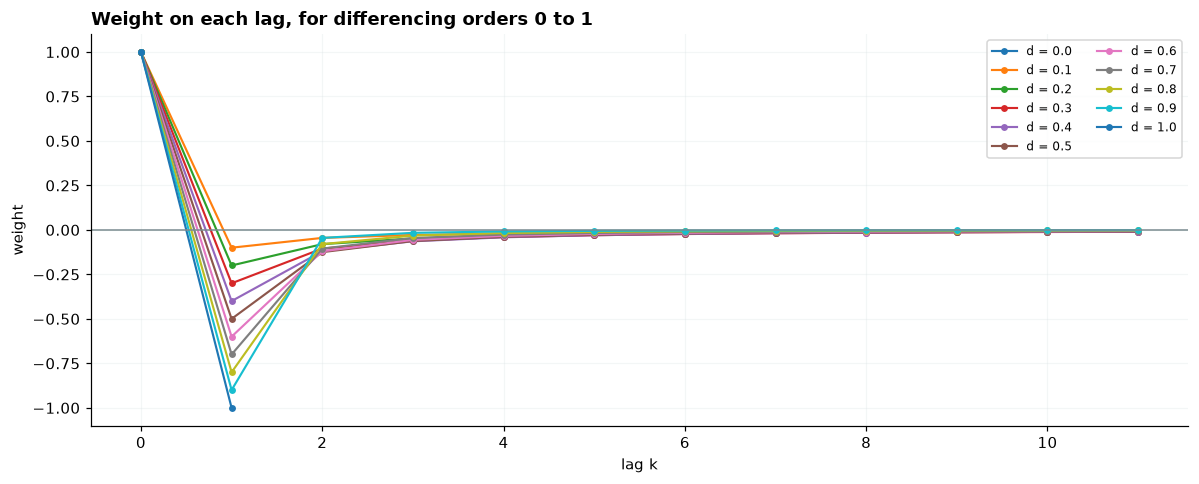

In [6]:
figure, axis = plt.subplots(figsize=(11, 4.5))
shown = 12

for d in np.arange(0, 1.01, 0.1):
    weights = fracdiff_weights(d, threshold=1e-6)[:shown]
    axis.plot(range(len(weights)), weights, marker="o", markersize=3.5,
              lw=1.4, label=f"d = {d:.1f}")

axis.axhline(0, color=GREY, lw=1)
axis.set_title("Weight on each lag, for differencing orders 0 to 1",
               loc="left", fontweight="bold")
axis.set_xlabel("lag k")
axis.set_ylabel("weight")
axis.legend(ncol=2, fontsize=8)

save("02_fracdiff_weights")
plt.show()

**What this chart tells me.** At d = 0 the line is flat at zero after the first
point: nothing is subtracted, so nothing is lost. At d = 1 the second weight
drops to −1 and everything after is zero: only yesterday matters, and all
earlier history is discarded in one step.

In between, the weights trail off gradually. **The slower the decay, the more
past observations still influence the current value, and the more memory the
series keeps.** That is the whole mechanism.

In [7]:
term_counts = pd.Series(
    {round(d, 1): len(fracdiff_weights(d)) for d in np.arange(0, 1.01, 0.1)},
    name="terms above threshold",
)
term_counts.to_frame()

,terms above threshold
0.0,1
0.1,503
0.2,497
0.3,388
0.4,282
0.5,200
0.6,140
0.7,97
0.8,64
0.9,38


### Applying the transformation

With the weights in hand, applying them is a convolution: slide the weight
vector along the series and take the dot product at each position.

I use the fixed-width version, which drops the first rows where there is not
enough history to fill the window. The alternative, an expanding window, uses
fewer weights early on and so produces a series whose properties change over
time. I want every output value computed the same way.

Two checks before I use it on anything real: at d = 0 the output must equal the
input, and at d = 1 it must equal the first difference.

In [9]:
def fracdiff(series, d, threshold=1e-4):
    """Fixed-width fractional differencing. Drops rows without enough history."""
    weights = fracdiff_weights(d, threshold)
    width = len(weights)

    values = pd.Series(series).dropna()

    if len(values) <= width:
        return pd.Series(dtype=float)

    transformed = np.convolve(values.to_numpy(dtype=float), weights, mode="valid")

    return pd.Series(transformed, index=values.index[width - 1 :])


spy_log = log_prices["SPY"]

at_zero = fracdiff(spy_log, 0.0)
at_one = fracdiff(spy_log, 1.0)

print(f"d = 0 reproduces the original : "
      f"{np.allclose(at_zero, spy_log.loc[at_zero.index])}")
print(f"d = 1 reproduces the first difference : "
      f"{np.allclose(at_one, spy_log.diff().loc[at_one.index])}")

d = 0 reproduces the original : True
d = 1 reproduces the first difference : True


The search

Now the actual experiment. For each order d from 0 to 1, I:

1. Apply the transformation to SPY log prices
2. Run the ADF test on the result
3. Measure the correlation between the transformed series and the original

Those last two are the trade-off in numbers. The ADF statistic should fall as d
rises, and the correlation should fall with it. **I want the smallest d where
the ADF statistic crosses −2.86**, because every step beyond that is memory
thrown away for nothing.

In [10]:
GRID = np.round(np.arange(0, 1.01, 0.05), 2)


def search_orders(series, grid=GRID, threshold=1e-4):
    """ADF statistic and correlation to the original, across differencing orders."""
    rows = []

    for d in grid:
        transformed = fracdiff(series, d, threshold)

        if transformed.empty:
            continue

        original = series.loc[transformed.index]

        rows.append({
            "d": d,
            "adf": adf_statistic(transformed),
            "correlation": np.corrcoef(transformed, original)[0, 1],
            "rows_kept": len(transformed),
            "weights": len(fracdiff_weights(d, threshold)),
        })

    table = pd.DataFrame(rows)
    table["stationary"] = table["adf"].apply(is_stationary)

    return table


spy_search = search_orders(spy_log)
spy_search.round(4)

,d,adf,correlation,rows_kept,weights,stationary
0,0.00,0.5893,1.0000,5032,1,False
1,0.05,0.2911,0.9997,4671,362,False
2,0.10,0.1659,0.9983,4530,503,False
3,0.15,-0.1454,0.9953,4506,527,False
4,0.20,-0.3964,0.9904,4536,497,False
5,0.25,-0.6923,0.9831,4588,445,False
6,0.30,-1.0556,0.9730,4645,388,False
7,0.35,-1.4581,0.9592,4701,332,False
8,0.40,-1.6804,0.9396,4751,282,False
9,0.45,-2.0236,0.9126,4795,238,False


In [11]:
passing = spy_search[spy_search["stationary"]]

if passing.empty:
    print("No order in the grid achieved stationarity.")
else:
    best = passing.iloc[0]
    baseline = spy_search[spy_search["d"] == 1.0].iloc[0]

    print(f"Minimum d that passes  : {best['d']:.2f}")
    print(f"  ADF statistic        : {best['adf']:.4f}  (threshold {ADF_CRITICAL[0.05]})")
    print(f"  Correlation retained : {best['correlation']:.4f}")
    print(f"  Rows kept            : {int(best['rows_kept']):,} of {len(spy_log):,}")
    print()
    print(f"Standard returns (d = 1.00)")
    print(f"  ADF statistic        : {baseline['adf']:.4f}")
    print(f"  Correlation retained : {baseline['correlation']:.4f}")
    print()
    print(f"Memory kept by stopping at d = {best['d']:.2f} instead of d = 1.00: "
          f"{best['correlation'] - baseline['correlation']:+.4f}")

Minimum d that passes  : 0.55
  ADF statistic        : -2.8857  (threshold -2.86)
  Correlation retained : 0.8258
  Rows kept            : 4,865 of 5,032

Standard returns (d = 1.00)
  ADF statistic        : -12.7448
  Correlation retained : 0.0228

Memory kept by stopping at d = 0.55 instead of d = 1.00: +0.8030


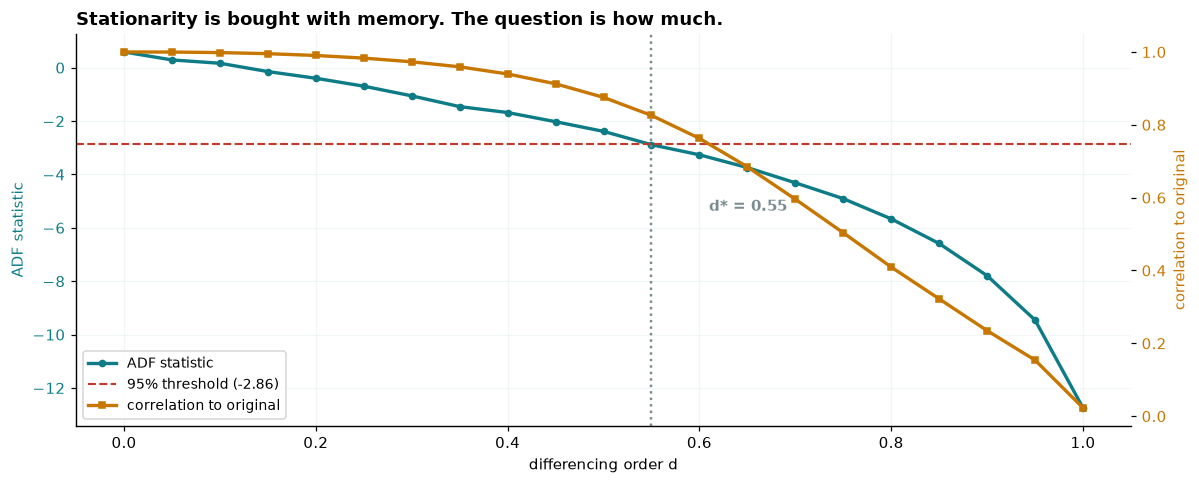

In [12]:
figure, left = plt.subplots(figsize=(11, 4.5))
right = left.twinx()

left.plot(spy_search["d"], spy_search["adf"], color=TEAL, lw=2.2,
          marker="o", markersize=4, label="ADF statistic")
left.axhline(ADF_CRITICAL[0.05], color=RED, ls="--", lw=1.4,
             label=f"95% threshold ({ADF_CRITICAL[0.05]})")
left.set_xlabel("differencing order d")
left.set_ylabel("ADF statistic", color=TEAL)
left.tick_params(axis="y", labelcolor=TEAL)

right.plot(spy_search["d"], spy_search["correlation"], color=AMBER, lw=2.2,
           marker="s", markersize=4, label="correlation to original")
right.set_ylabel("correlation to original", color=AMBER)
right.tick_params(axis="y", labelcolor=AMBER)
right.grid(False)

if not passing.empty:
    left.axvline(best["d"], color=GREY, ls=":", lw=1.6)
    left.annotate(f"d* = {best['d']:.2f}", xy=(best["d"], ADF_CRITICAL[0.05]),
                  xytext=(best["d"] + 0.06, ADF_CRITICAL[0.05] - 2.5),
                  fontsize=10, fontweight="bold", color=GREY)

left.set_title("Stationarity is bought with memory. The question is how much.",
               loc="left", fontweight="bold")

lines = left.get_lines()[:2] + right.get_lines()[:1]
left.legend(lines, [line.get_label() for line in lines], loc="lower left", fontsize=9)

save("02_fracdiff_search")
plt.show()

**How to read this chart.** The teal line falling through the red dashed
threshold is the series becoming stationary. The amber line falling is memory
being lost. The dotted vertical marks the point where the first has happened and
the second has not yet gone too far.

Everything to the right of that line is memory spent for no statistical gain.
Taking plain returns puts you at the far right edge.

### Seeing the memory

The correlation number is abstract, so I want to look at the actual series. Three
panels: the original log price, the transformed series at the minimum passing d,
and the standard log return.

If the middle panel still traces the shape of the first while fluctuating around
a stable level, that is memory and stationarity together. If the right panel
looks like pure noise with no resemblance to the first, that is what taking
returns costs.

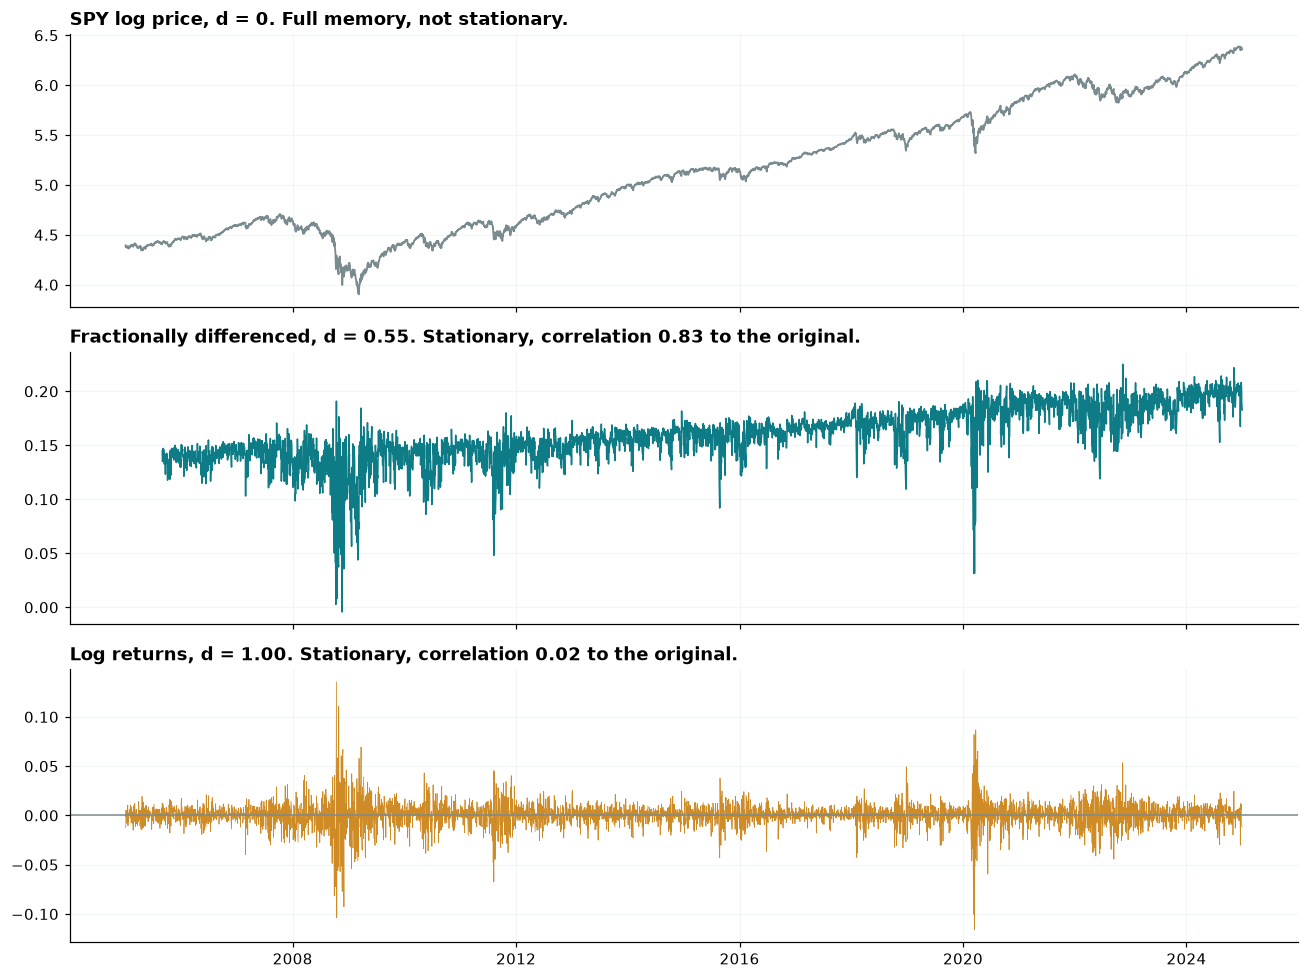

In [13]:
if not passing.empty:
    d_star = best["d"]
    transformed = fracdiff(spy_log, d_star)
    returns = spy_log.diff().dropna()

    figure, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

    axes[0].plot(spy_log.index, spy_log, color=GREY, lw=1.2)
    axes[0].set_title("SPY log price, d = 0. Full memory, not stationary.",
                      loc="left", fontweight="bold")

    axes[1].plot(transformed.index, transformed, color=TEAL, lw=1.0)
    axes[1].set_title(
        f"Fractionally differenced, d = {d_star:.2f}. "
        f"Stationary, correlation {best['correlation']:.2f} to the original.",
        loc="left", fontweight="bold")

    axes[2].plot(returns.index, returns, color=AMBER, lw=0.5, alpha=0.85)
    axes[2].axhline(0, color=GREY, lw=1)
    axes[2].set_title(
        f"Log returns, d = 1.00. Stationary, correlation "
        f"{baseline['correlation']:.2f} to the original.",
        loc="left", fontweight="bold")

    save("02_memory_comparison")
    plt.show()

### Does the answer hold across every ticker?

One result on SPY could be a quirk of the index. The paper found that all 87
liquid futures it tested reached stationarity below d = 0.6, and most below 0.3.
I want to know whether my eleven names agree.

If they cluster tightly I can use one order for the whole universe, which is
simpler and less prone to overfitting. If they scatter widely I need to think
about whether a per-ticker order is justified or whether I am just fitting noise.

In [14]:
per_ticker = []

for ticker, series in log_prices.items():
    table = search_orders(series)
    passing_here = table[table["stationary"]]

    if passing_here.empty:
        per_ticker.append({"ticker": ticker, "d_star": np.nan})
        continue

    row = passing_here.iloc[0]
    at_one = table[table["d"] == 1.0].iloc[0]

    per_ticker.append({
        "ticker": ticker,
        "d_star": row["d"],
        "adf_at_d_star": row["adf"],
        "corr_at_d_star": row["correlation"],
        "corr_at_d_one": at_one["correlation"],
        "memory_gained": row["correlation"] - at_one["correlation"],
        "rows_lost": len(series) - int(row["rows_kept"]),
    })

orders = pd.DataFrame(per_ticker).set_index("ticker").sort_values("d_star")
orders.round(4)

,d_star,adf_at_d_star,corr_at_d_star,corr_at_d_one,memory_gained,rows_lost
ticker,,,,,,
GE,0.25,-3.1354,0.9045,0.0311,0.8734,444
INTC,0.30,-3.1201,0.8934,0.0176,0.8758,387
XOM,0.30,-3.2612,0.8760,0.0241,0.8519,387
KO,0.45,-2.9764,0.8730,0.0075,0.8655,237
PG,0.50,-3.1422,0.8457,0.0176,0.8281,199
JPM,0.50,-3.0536,0.7591,0.0261,0.7330,199
JNJ,0.50,-2.9656,0.8671,0.0086,0.8585,199
SPY,0.55,-2.8857,0.8258,0.0228,0.8030,167
WMT,0.55,-3.0566,0.8016,0.0342,0.7673,167


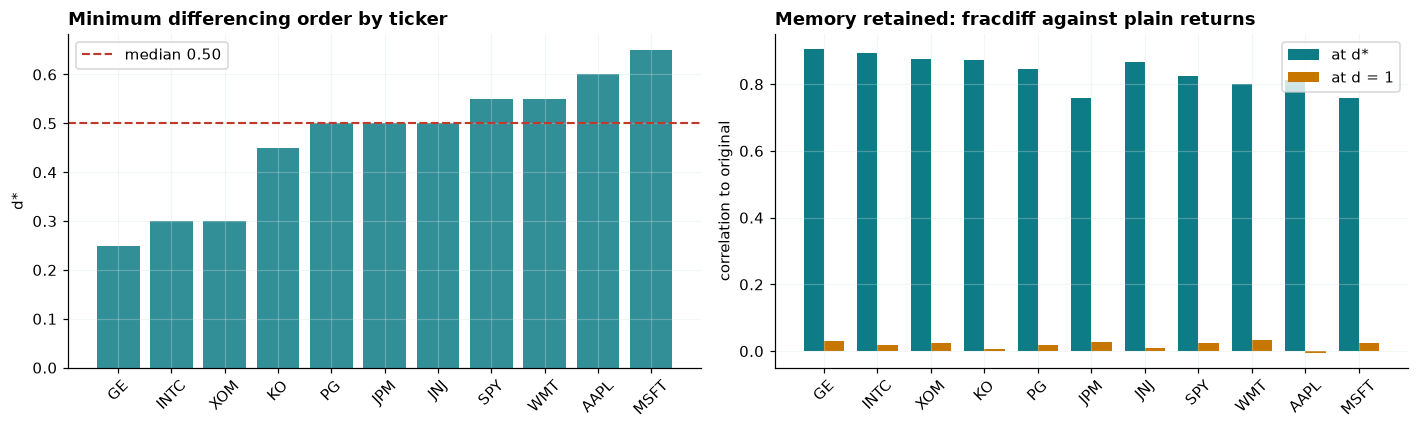

d* range: 0.25 to 0.65
d* median: 0.50
Mean memory gained over plain returns: 0.819


In [15]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(orders.index, orders["d_star"], color=TEAL, alpha=0.85)
axes[0].axhline(orders["d_star"].median(), color=RED, ls="--", lw=1.4,
                label=f"median {orders['d_star'].median():.2f}")
axes[0].set_title("Minimum differencing order by ticker", loc="left", fontweight="bold")
axes[0].set_ylabel("d*")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

width = 0.38
positions = np.arange(len(orders))
axes[1].bar(positions - width / 2, orders["corr_at_d_star"], width=width,
            color=TEAL, label="at d*")
axes[1].bar(positions + width / 2, orders["corr_at_d_one"], width=width,
            color=AMBER, label="at d = 1")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(orders.index, rotation=45)
axes[1].set_title("Memory retained: fracdiff against plain returns",
                  loc="left", fontweight="bold")
axes[1].set_ylabel("correlation to original")
axes[1].legend()

save("02_per_ticker")
plt.show()

print(f"d* range: {orders['d_star'].min():.2f} to {orders['d_star'].max():.2f}")
print(f"d* median: {orders['d_star'].median():.2f}")
print(f"Mean memory gained over plain returns: {orders['memory_gained'].mean():.3f}")

In [16]:
at_zero_only = pd.DataFrame([
    {"ticker": ticker, "adf_raw_log_price": adf_statistic(series)}
    for ticker, series in log_prices.items()
]).set_index("ticker").sort_values("adf_raw_log_price")

at_zero_only["passes_undifferenced"] = at_zero_only["adf_raw_log_price"].apply(is_stationary)

flagged = at_zero_only[at_zero_only["passes_undifferenced"]]

if flagged.empty:
    print("No ticker passes undifferenced. Every d* is a genuine result.")
else:
    print(f"{len(flagged)} ticker(s) pass the test on raw log prices:")
    print(flagged.round(3).to_string())
    print()
    print("Treat these with suspicion. A price series that looks stationary over")
    print("one window is usually a random walk that happened to end near its start.")

at_zero_only.round(3)

No ticker passes undifferenced. Every d* is a genuine result.


,adf_raw_log_price,passes_undifferenced
ticker,,
GE,-1.699,False
INTC,-1.415,False
XOM,-1.213,False
KO,-0.862,False
AAPL,-0.848,False
JNJ,-0.556,False
PG,-0.152,False
JPM,0.122,False
SPY,0.589,False


### Does it survive out of sample?

One thing that would quietly invalidate all of this: if d* is itself unstable
over time. If the first half of my sample needs 0.3 and the second half needs
0.7, then choosing a single order on the full sample is a form of look-ahead,
because I used the whole history to make a decision that affects early rows.

I split SPY in half and run the search separately on each.

In [17]:
half = len(spy_log) // 2
segments = {"first half": spy_log.iloc[:half], "second half": spy_log.iloc[half:]}

stability = []

for label, segment in segments.items():
    table = search_orders(segment)
    passing_here = table[table["stationary"]]

    stability.append({
        "segment": label,
        "rows": len(segment),
        "d_star": passing_here.iloc[0]["d"] if not passing_here.empty else np.nan,
        "adf_at_d_star": passing_here.iloc[0]["adf"] if not passing_here.empty else np.nan,
    })

pd.DataFrame(stability).set_index("segment").round(4)

,rows,d_star,adf_at_d_star
segment,,,
first half,2516,0.50,-3.2228
second half,2516,0.45,-3.2896


### Is it actually worth using?

The honest question. Fractional differencing is more complex than
`.pct_change()`, and complexity has to earn its place.

The argument in favour is that it keeps information a return series throws away,
and that information is what the model needs to predict from. The argument
against is that it costs warm-up rows, adds a parameter, and I have not yet
shown it improves anything I care about.

What I can check here is whether the transformed series carries more
autocorrelation than plain returns. Notebook 01 found return autocorrelation
close to zero. If the fracdiff series has meaningfully more structure, there is
something for a model to work with.

In [18]:
if not passing.empty:
    fd_series = fracdiff(spy_log, d_star)
    plain_returns = spy_log.diff().dropna()

    lags = range(1, 11)
    structure = pd.DataFrame(
        {
            f"fracdiff d={d_star:.2f}": [fd_series.autocorr(lag) for lag in lags],
            "log returns": [plain_returns.autocorr(lag) for lag in lags],
        },
        index=pd.Index(lags, name="lag"),
    )

    band = 1.96 / np.sqrt(len(plain_returns))
    print(f"Significance band: +/-{band:.4f}")
    print()
    print(structure.round(4).to_string())

Significance band: +/-0.0276

     fracdiff d=0.55  log returns
lag                              
1             0.8257      -0.1004
2             0.7949      -0.0157
3             0.7786       0.0157
4             0.7568      -0.0292
5             0.7476      -0.0145
6             0.7389      -0.0347
7             0.7467       0.0543
8             0.7291      -0.0399
9             0.7356       0.0399
10            0.7248      -0.0039
